In [ ]:
import sys
if "../" not in sys.path:
    sys.path.append("../")
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import autobnn
from autobnn import estimators, training_util
from autobnn import kernels, likelihoods

from src.utils import barrier_dist, point_diff

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.wong import sigma
import scienceplots
plt.style.use(['science', 'no-latex', 'ieee'])

plt.rc('axes', labelsize=14) 
plt.rcParams['axes.titlesize'] = 20
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('legend', fontsize=10)  
plt.rc('lines', linewidth=2)


import scipy as sp
import os
from scipy.optimize import curve_fit
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, ConstantKernel, ExpSineSquared, RationalQuadratic
import findiff as fd

Best-fit parameters:
  E0    = 73.3846 ± 0.0047 MeV
  R0    = 10.2260 ± 0.0078 fm
  hbarw = 4.8410 ± 0.0074 MeV


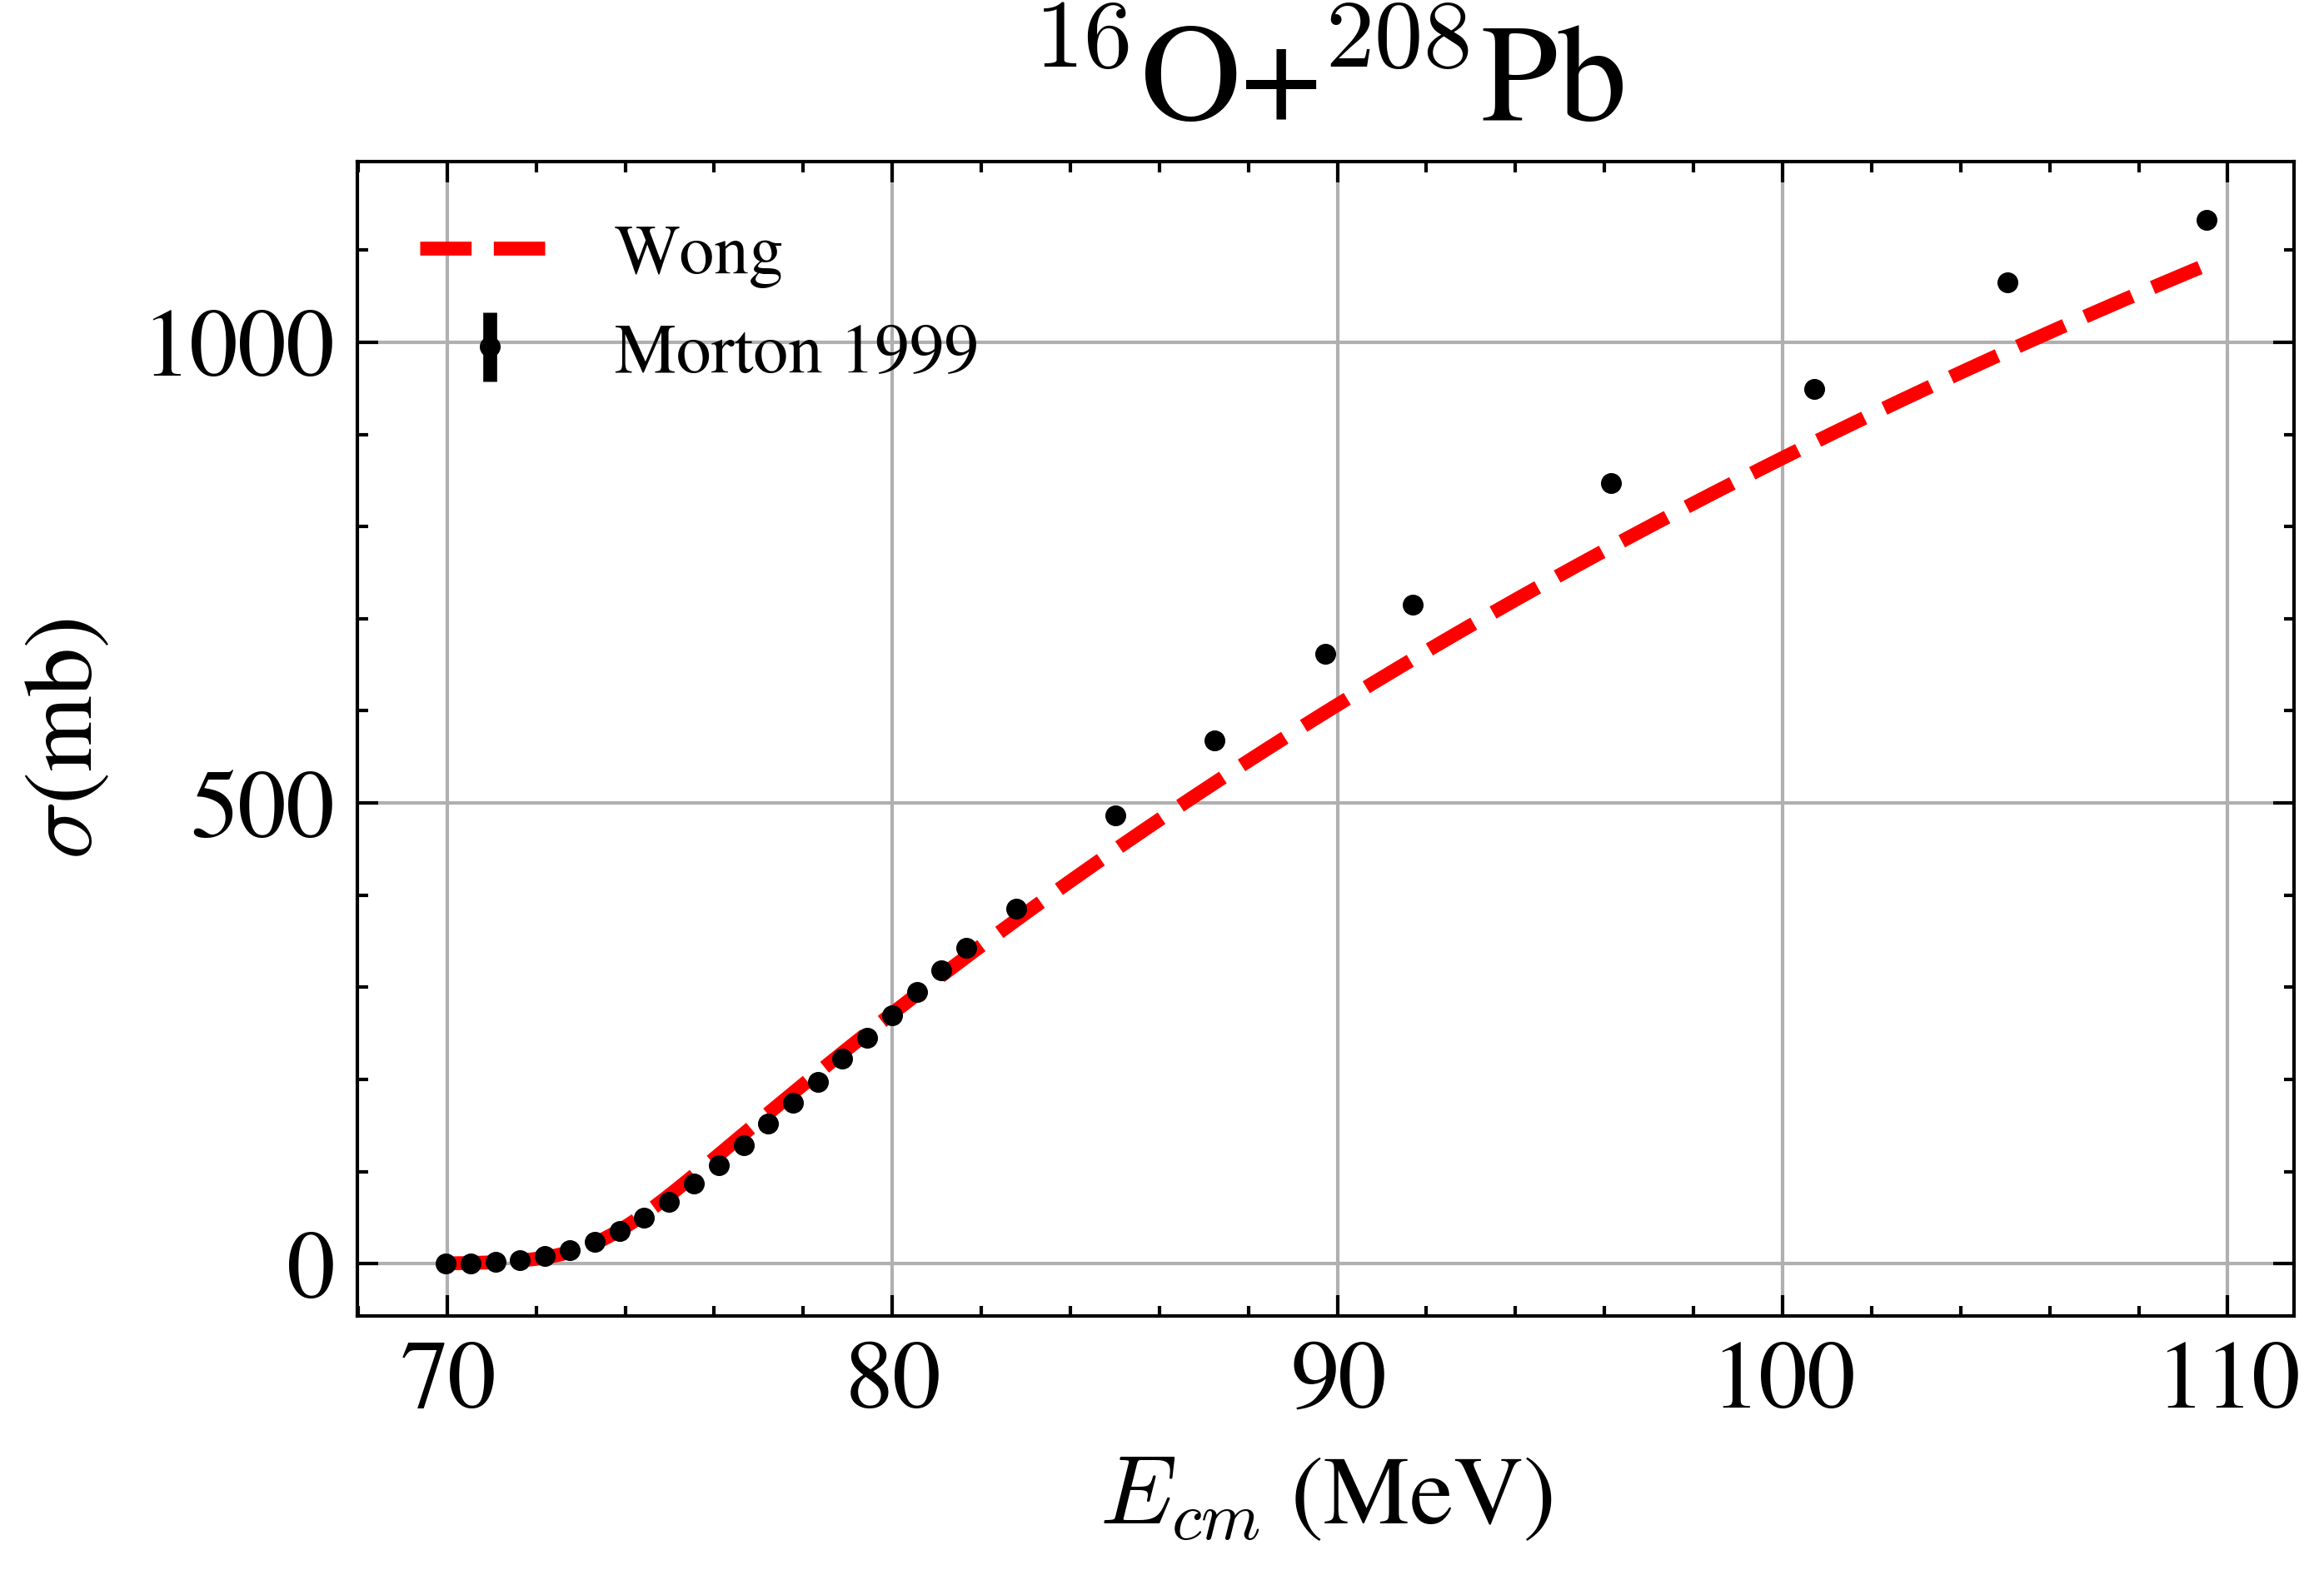

In [3]:
dirname = "/Users/aaronphilip/Senior Thesis/barrier-distribution-sample/16O208Pb_exp"
system = "$^{208}$Pb+$^{16}$O"
fileprefix = dirname

expfiles = [ 'expMort.dat', 'expDas.dat' ]
explabel = [ 'Morton et al. 1999', 'Dasgupta et al. 2007' ]
expmarker = [ 'o', 's' ]
expcolor = [ 'k', 'g' ]

exp = []

for file in expfiles:
    tmpdf = pd.read_csv(os.path.join(dirname,file),sep='\s+',names=['Ecm','Sigma','Error'])
    if(tmpdf['Ecm'].iloc[0] > tmpdf['Ecm'].iloc[-1]):
        exp.append(tmpdf.iloc[::-1])
    else:
        exp.append(tmpdf)

xmin = 70.0
xmax = 90.0


E_data = exp[0]['Ecm'].to_numpy()
Sigma_data = exp[0]['Sigma'].to_numpy()
Sigma_err  = exp[0]['Error'].to_numpy()


# --- Initial guesses for [E0, R0, hbarw] ---
# You may need to tweak these based on your system.
initial_guess = [70.0, 11.0, 4]  # e.g. E0≈10MeV, R0≈7fm, ħω≈4MeV

# --- Perform the fit ---
popt, pcov = curve_fit(
    sigma,
    E_data,
    Sigma_data,
    p0=initial_guess,
    sigma=Sigma_err,
    absolute_sigma=True,
    # bounds can help keep parameters physical:
    bounds=([0.0, 8.0, 0.0], [np.inf, 15.0, np.inf])
)

E0_opt, R0_opt, hbarw_opt = popt
perr = np.sqrt(np.diag(pcov))

print(f"Best-fit parameters:")
print(f"  E0    = {E0_opt:.4f} ± {perr[0]:.4f} MeV")
print(f"  R0    = {R0_opt:.4f} ± {perr[1]:.4f} fm")
print(f"  hbarw = {hbarw_opt:.4f} ± {perr[2]:.4f} MeV")

# --- Plot experiment vs. fit ---
E_plot = np.linspace(E_data.min(), E_data.max(), 500)
Sigma_fit = sigma(E_plot, E0_opt, R0_opt, hbarw_opt)

plt.figure(figsize=(5,3))
plt.errorbar(E_data, Sigma_data, yerr=Sigma_err, fmt='o', label='Morton 1999', markersize=2)
#plt.scatter(E_data, Sigma_data, label='Morton 1999', color='k', s=10)
plt.plot(E_plot, Sigma_fit, label='Wong')
plt.xlabel(r'$E_{cm}$ (MeV)')
plt.ylabel(r'$\sigma$(mb)')
plt.title("$^{16}$O+$^{208}$Pb")
plt.legend()
plt.grid(True)
#plt.tight_layout()
plt.show()

In [4]:
N = 1000
total_E = np.concatenate((exp[0]['Ecm'].to_numpy(), exp[1]['Ecm'].to_numpy()))
E_fine = np.linspace(total_E.min(), total_E.max(), N)

# Number of Monte‐Carlo draws to propagate parameter‐uncertainty:
M = 200 

# Covariance of (E0,R0,hbarw) from your fit:
P_cov = pcov        # shape (3,3) 

# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  1) Draw M parameter‐samples from  N(popt, pcov)                             │
# └─────────────────────────────────────────────────────────────────────────────┘
# Each row of `param_samples` is (E0_j, R0_j, hbarw_j).
param_samples = np.random.multivariate_normal(
    mean=[E0_opt, R0_opt, hbarw_opt],
    cov=P_cov,
    size=M
)  # shape (M,3)

# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  2) For each of those M sets, compute σ_j(E_data)                            │
# └─────────────────────────────────────────────────────────────────────────────┘
# We'll build a matrix S of shape (M, N) where
#    S[j,i] = σ( E_fine[i];  E0_j, R0_j, hbarw_j ).
S = np.empty((M, N))

for j in range(M):
    E0_j, R0_j, hbarw_j = param_samples[j]
    # Evaluate your analytic sigma‐function on the entire E_fine grid:
    S[j, :] = sigma(E_fine, E0_j, R0_j, hbarw_j)

# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  3) Compute the Monte‐Carlo mean and variance at each E_data[i]               │
# └─────────────────────────────────────────────────────────────────────────────┘
#   mean over j:  shape → (N,)
sigma_mean = S.mean(axis=0)
#   var  over j:  shape → (N,)
sigma_var  = S.var(axis=0, ddof=1)   # unbiased estimate of Var[σ(E_i)]

# If any σ_var[i] happens to be exactly zero (i.e. all S[:,i] identical),
# add a tiny floor so the GP doesn't complain about zero‐noise.
sigma_var += 1e-16

In [5]:
# Create a training set for the GP:
#fine_interval = 10
#coarse_interval = 10
start = 0#np.argmin(np.abs(E_fine - 75.0))
mid = np.argmin(np.abs(E_fine- 80.0))
stop = np.argmin(np.abs(E_fine- 90.0))
E_train = E_fine#np.concatenate((E_fine[start:mid:fine_interval], E_fine[mid:stop:coarse_interval]))
#E_train = E_fine[start:stop:interval]

sigma_train = sigma_mean#np.concatenate((sigma_mean[start:mid:fine_interval], sigma_mean[mid:stop:coarse_interval]))#sigma_mean[start:stop:interval]
sigma_train_var = sigma_var#np.concatenate((sigma_var[start:mid:fine_interval], sigma_var[mid:stop:coarse_interval]))#sigma_var[start:stop:interval]
#gp = train_gp(E_train, sigma_mu_train=sigma_train, sigma_var_train=1e-8)#np.zeros_like(sigma_train_var))


In [13]:
# 1) Initialize PRNG
seed = jax.random.PRNGKey(0)

# 3) Normalize inputs once
x_scale = np.std(E_train)
x_shift = np.mean(E_train)
y_scale = np.std(sigma_train)
y_shift = np.mean(sigma_train)

x_norm = ((E_train - x_shift) / x_scale)[..., None]
y_norm = ((sigma_train-y_shift) / y_scale)[..., None]

# 4) Build & train the AutoBnnMapEstimator
seed, est_seed = jax.random.split(seed)
rbf = kernels.ExponentiatedQuadraticBNN()
bnn_est = estimators.AutoBnnMapEstimator(
    rbf,#'sum_of_products',              
    likelihood_model='normal_likelihood_logistic_noise',
    seed=est_seed,
    num_particles=32,
    width=50,
    #num_chains=4,
    #num_draws=20,
)
bnn_est = bnn_est.fit(x_norm, y_norm)

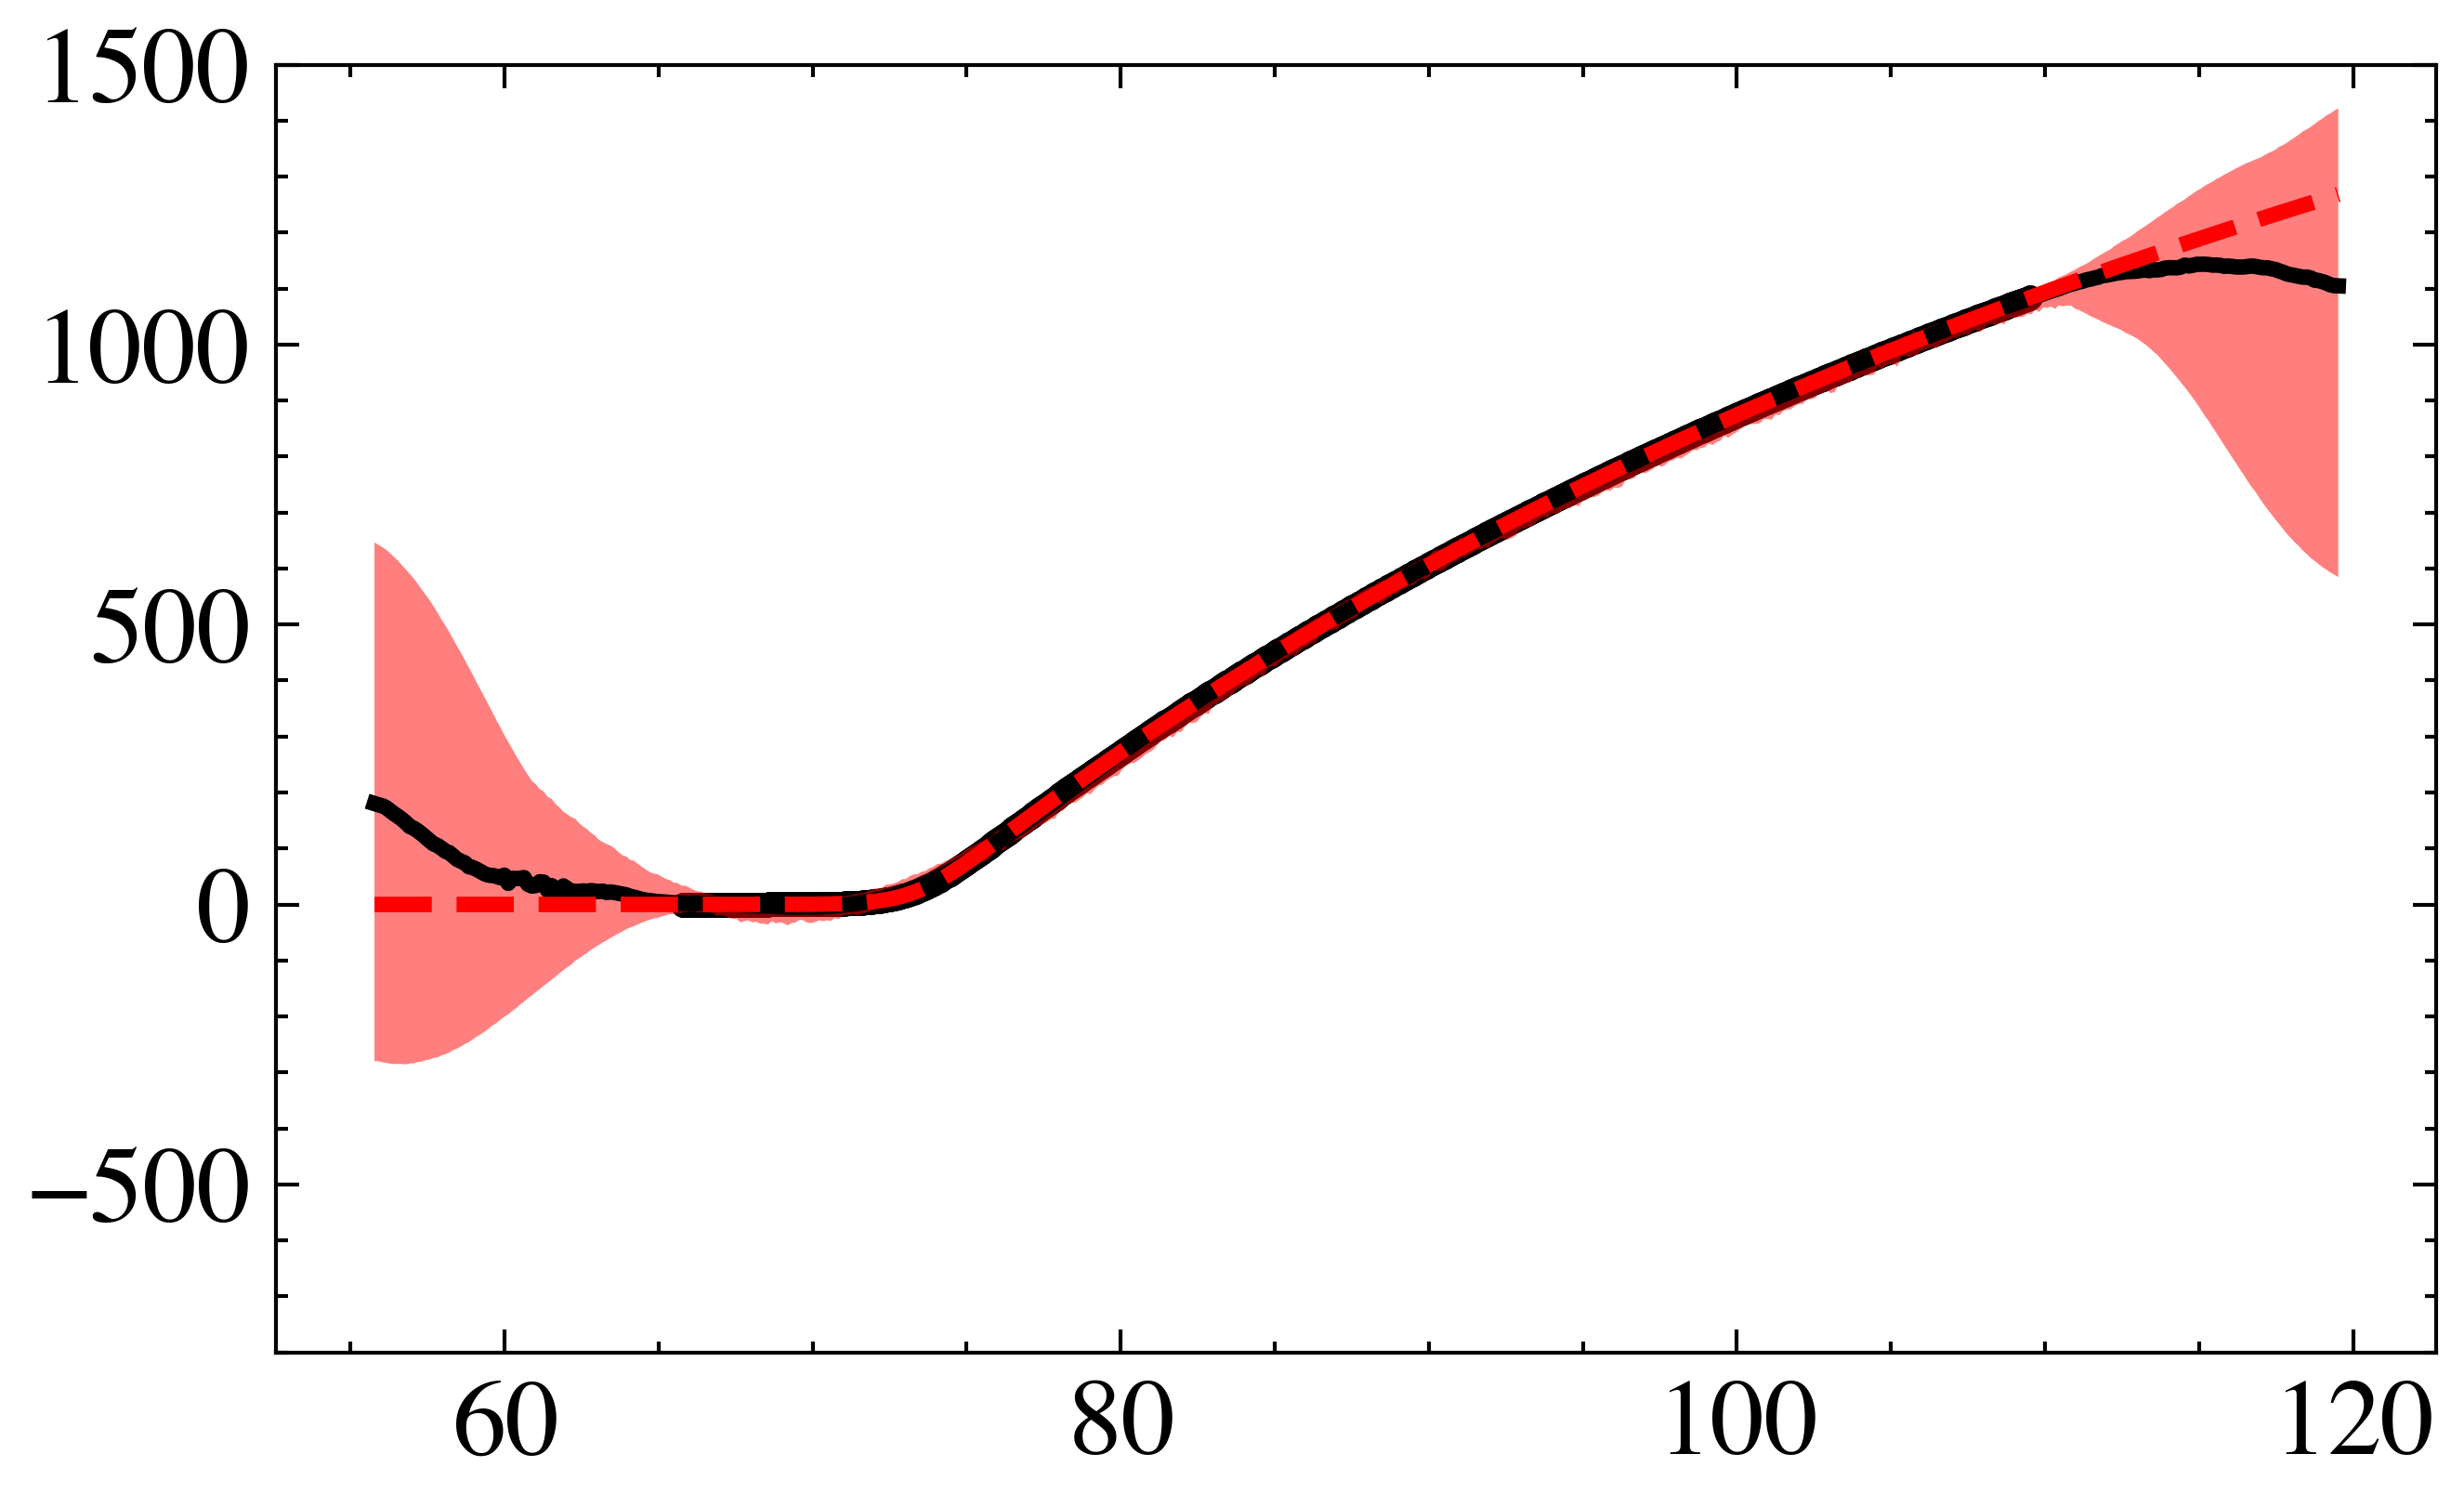

In [14]:
E_eval   = np.linspace(E_fine.min() - 10, E_fine.max() + 10, 500)

# 5) Prediction grid (physical → normalized)
x_pred = E_eval #np.linspace(E_train.min(), E_train.max(), 99)
x_pred_norm = (x_pred- x_shift) / x_scale

# 6) Get per-particle means and noise‐draws
#    estimator.predict returns a dict with keys 'mean' and 'std' of shape (num_particles, n_x)
pred = bnn_est.predict(x_pred_norm[..., None]) * y_scale + y_shift
# Draw 100 noisy samples per particle
seed, draw_seed = jax.random.split(seed)
# we broadcast sample_shape over both axes

lo, mid, p90, hi = bnn_est.predict_quantiles(x_pred_norm[..., None], q=[2.5, 50., 90., 97.5]) * y_scale + y_shift

plt.figure(figsize=(5, 3))
plt.plot(x_pred, mid.squeeze(), label="BNN")
plt.plot(E_eval, sigma(E_eval, E0_opt, R0_opt, hbarw_opt), label='Wong', color='C1', linestyle='--')
plt.scatter(E_train, sigma_train, s=5)
plt.fill_between(
    x_pred,
    lo.squeeze(), hi.squeeze(),
    alpha=0.5,
    label="95% confidence BNN ",
)
plt.ylim(-800, 1500)
plt.show()

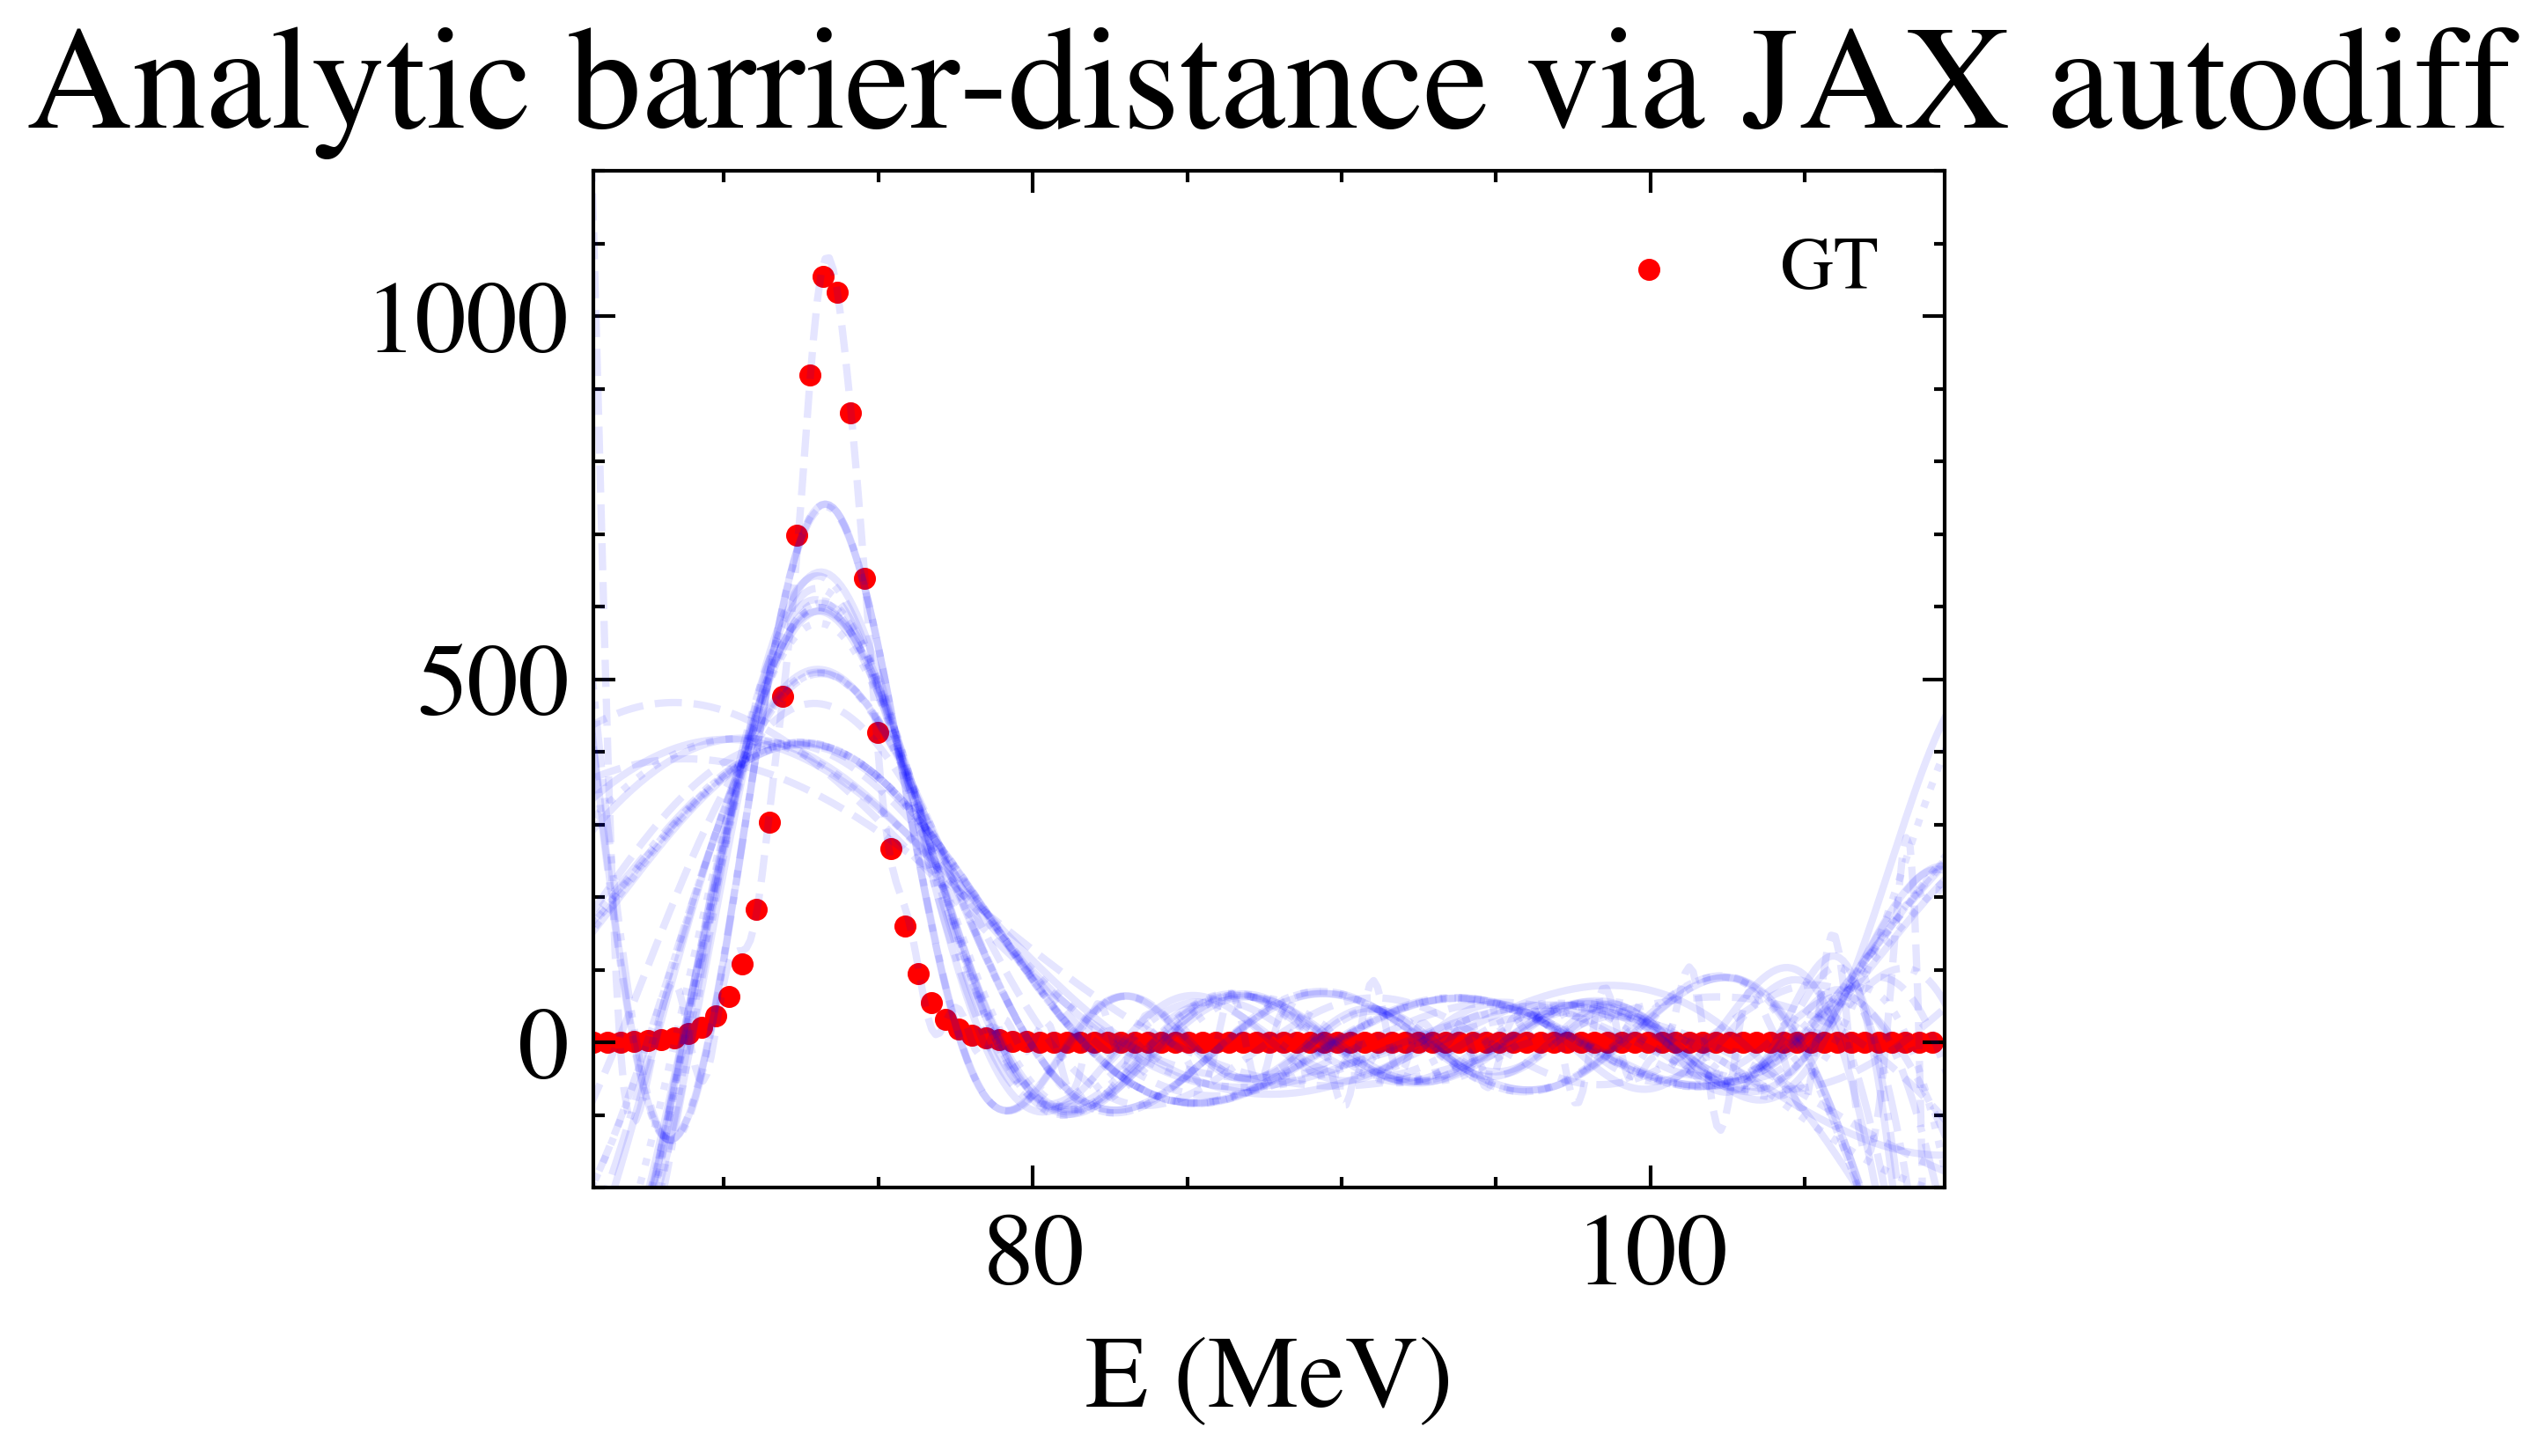

In [15]:
draws = bnn_est.likelihood_.sample(
                    bnn_est.params_['params'], pred.squeeze(), seed=seed, sample_shape=100)
#draws = draws.reshape(-1, draws.shape[-1])

# number of particles
P = draws.shape[1]

# shortcut to the trained net and params
net    = bnn_est.net_
params = bnn_est.params_


# 1) Define a scalar function for a single particle i:
#    f_i(x) = x * σ_p(x), where σ_p is the BNN mean for particle p=i.
def f_i(i, x):
    # normalize and shape for predict:
    x_norm = jnp.array([[(x - x_shift) / x_scale]])
    # make_predictions returns shape (P, 1, 1)  => loc[p,0,0] is σ_p(x_norm)
    loc = training_util.make_predictions(params, net=net, x_test=x_norm)*y_scale + y_shift
    return x * loc[i, 0, 0]   # scalar

# 2) Build a jitted function that for a given i and x returns d²f_i/dx²
#    by nesting two grads.
d2_f_i = jax.jit(
    lambda i, x: jax.grad(jax.grad(lambda xx: f_i(i, xx), argnums=0), argnums=0)(x)
)

# 3) Vectorize over particle index i and then over x_pred
#    Result will be shape (P, n_x)
d2_over_particles = jax.vmap(
    lambda i: jax.vmap(lambda xx: d2_f_i(i, xx))(x_pred),
    in_axes=0
)(jnp.arange(P))

# 4) Plot exactly as you did before
plt.figure()
n_cut = 0
for p in range(P):
    y = np.array(d2_over_particles[p, n_cut:-n_cut-1])
    plt.plot(x_pred[n_cut:-n_cut-1], y, lw=1, alpha=0.1, color='b')

spacing=10
true = barrier_dist(E_train,sigma(E_train,E0_opt,R0_opt,hbarw_opt),acc=4)
plt.scatter(E_train[::spacing], true[::spacing], color='r', s=4, label='GT')

plt.xlabel("E (MeV)")
#plt.ylabel(r"$\dfrac{d^2}{dE^2}\bigl[E\,\sigma(E)\bigr]$")
plt.title("Analytic barrier-distance via JAX autodiff")
plt.ylim([-200, 1200])
plt.xlim(E_train[0], E_train[-1])
plt.legend()
plt.show()